In [21]:
!pip install datasets scikit-learn -q

In [22]:
from datasets import load_dataset
import torch

ds_test = load_dataset("dinushiTJ/nz_research_commons_inference_results", split="train")
display(ds_test)

Dataset({
    features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'BaseEmbGemZeroLabel', 'BaseEmbGemZeroID', 'BaseEmbGemZeroScore', 'Base4BResponse', 'FTEmbGemZeroLabel', 'FTEmbGemZeroID', 'FTEmbGemZeroScore'],
    num_rows: 3318
})

In [23]:
print(ds_test.column_names)

['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'BaseEmbGemZeroLabel', 'BaseEmbGemZeroID', 'BaseEmbGemZeroScore', 'Base4BResponse', 'FTEmbGemZeroLabel', 'FTEmbGemZeroID', 'FTEmbGemZeroScore']


In [24]:
print(ds_test.features)

{'title': Value('string'), 'authors': Value('string'), 'subjects': Value('string'), 'abstract': Value('string'), 'text': Value('string'), 'record_id_hash': Value('string'), 'prompt': Value('string'), 'token_count': Value('int32'), 'classification_label': ClassLabel(names=['maori_origin', 'non_maori_origin']), 'classification_reason': Value('string'), 'year': Value('string'), 'classification_confidence': Value('float32'), 'embedding_text': Value('string'), 'embedding_token_count': Value('int64'), 'BaseEmbGemZeroLabel': Value('string'), 'BaseEmbGemZeroID': Value('int64'), 'BaseEmbGemZeroScore': Value('float64'), 'Base4BResponse': Value('string'), 'FTEmbGemZeroLabel': Value('string'), 'FTEmbGemZeroID': Value('int64'), 'FTEmbGemZeroScore': Value('float64')}


### Dataset Evaluation

Now, let's evaluate the dataset using the `classification_label` as the true labels and `FTEmbGemZeroLabel` as the predicted labels.

In [25]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score

# ClassLabel feature
class_label = ds_test.features["classification_label"]

# Ground truth IDs
true_labels_id = ds_test["classification_label"]

# Ground truth strings
true_labels = [
    class_label.int2str(label_id)
    for label_id in true_labels_id
]

# Predicted strings
pred_labels = ds_test["FTEmbGemZeroLabel"]

# Predicted IDs
predicted_labels_id = [
    class_label.str2int(label)
    for label in pred_labels
]

print(f"Unique true labels: {set(true_labels)}")
print(f"Unique true labels (IDs): {set(true_labels_id)}")

print(f"Unique predicted labels: {set(pred_labels)}")
print(f"Unique predicted labels (IDs): {set(predicted_labels_id)}")

Unique true labels: {'maori_origin', 'non_maori_origin'}
Unique true labels (IDs): {0, 1}
Unique predicted labels: {'maori_origin', 'non_maori_origin'}
Unique predicted labels (IDs): {0, 1}


In [26]:
label_names = class_label.names
label_to_id = {name: i for i, name in enumerate(label_names)}

In [27]:
# Calculate Confusion Matrix
conf_matrix = confusion_matrix(true_labels_id, predicted_labels_id, labels=[label_to_id[name] for name in label_names])
print("Confusion Matrix (task labels only):")
print(conf_matrix)

# Calculate Classification Report
class_report = classification_report(true_labels_id, predicted_labels_id, target_names=label_names, digits=4)
print("\nClassification Report (task labels only):")
print(class_report)

# Calculate Accuracy
accuracy = accuracy_score(true_labels_id, predicted_labels_id)
print(f"\nAccuracy: {accuracy:.4f}")

# Calculate F1 Score (macro and weighted)
f1_macro = f1_score(true_labels_id, predicted_labels_id, average='macro')
f1_weighted = f1_score(true_labels_id, predicted_labels_id, average='weighted')
print(f"F1 Macro: {f1_macro:.4f}")
print(f"F1 Weighted: {f1_weighted:.4f}")

# Combine metrics into a dictionary as shown in the example
metrics = {
    'accuracy': accuracy,
    'f1_macro': f1_macro,
    'f1_weighted': f1_weighted
}
print(f"\nCombined Metrics: {metrics}")

Confusion Matrix (task labels only):
[[ 324   43]
 [  41 2910]]

Classification Report (task labels only):
                  precision    recall  f1-score   support

    maori_origin     0.8877    0.8828    0.8852       367
non_maori_origin     0.9854    0.9861    0.9858      2951

        accuracy                         0.9747      3318
       macro avg     0.9366    0.9345    0.9355      3318
    weighted avg     0.9746    0.9747    0.9747      3318


Accuracy: 0.9747
F1 Macro: 0.9355
F1 Weighted: 0.9747

Combined Metrics: {'accuracy': 0.9746835443037974, 'f1_macro': 0.9355091296814607, 'f1_weighted': 0.9746532469993717}


### Precision-Recall Curve

The Precision-Recall curve is particularly useful for evaluating binary classifiers on imbalanced datasets. It shows the trade-off between precision and recall for different threshold settings.

Area Under the Precision-Recall Curve (AUPRC): 0.9358


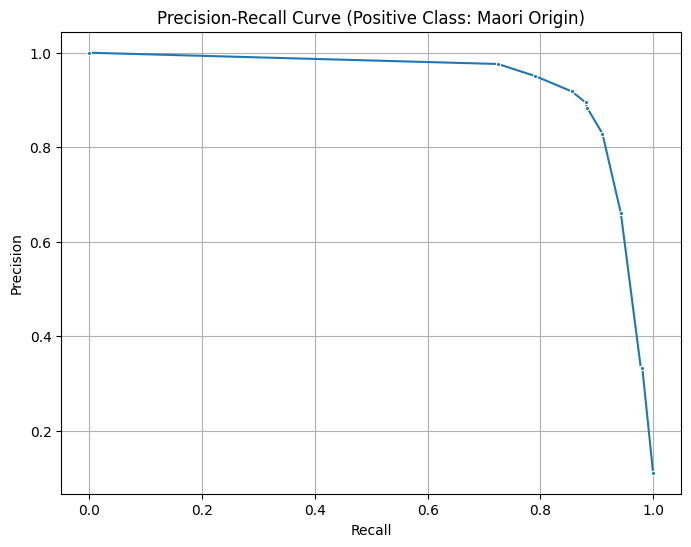

In [28]:
from sklearn.metrics import precision_recall_curve, roc_auc_score, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming `ds_test` contains 'classification_confidence' for the positive class (maori_origin=0)
# We need the probabilities of the positive class. The `classification_confidence` might be for the predicted class.
# If FTEmbGemZeroLabel is 'maori_origin' (0), then this confidence is for 0. Otherwise for 1.
# For the PR curve, we need the score for one specific class, typically the positive class.

# Let's assume 'maori_origin' is the positive class (label 0) for the PR curve.
# We need to extract the confidence scores for the 'maori_origin' class.
# The 'classification_confidence' in the dataset is the confidence of the *predicted* class.
# If the predicted class (FTEmbGemZeroID) is 0, then classification_confidence is P(class=0).
# If the predicted class (FTEmbGemZeroID) is 1, then classification_confidence is P(class=1).
# We need P(class=0) specifically.

# For simplicity, if `classification_confidence` is always P(predicted_label), we need to derive P(maori_origin).
# P(maori_origin) = classification_confidence if predicted label is maori_origin
# P(maori_origin) = 1 - classification_confidence if predicted label is non_maori_origin

# Or, a simpler assumption: `classification_confidence` directly refers to the positive class (e.g., class 0 'maori_origin')
# If this is not the case, the calculation of `y_scores` would need adjustment.

# Let's define the positive class as 'maori_origin' (label 0)
positive_class_label_id = label_to_id['maori_origin']

# Create a list of scores for the positive class
# This assumes classification_confidence is for the predicted label.
# We want the confidence for 'maori_origin' (label 0)
# If FTEmbGemZeroID is 0, use classification_confidence. If FTEmbGemZeroID is 1, use 1 - classification_confidence.

y_scores = []
for i in range(len(ds_test)):
    if ds_test[i]['FTEmbGemZeroID'] == positive_class_label_id:
        y_scores.append(ds_test[i]['classification_confidence'])
    else:
        y_scores.append(1 - ds_test[i]['classification_confidence'])

# Convert true_labels_id to binary (1 for positive_class, 0 otherwise)
y_true_binary = [1 if label_id == positive_class_label_id else 0 for label_id in true_labels_id]

# Calculate precision and recall
precision, recall, thresholds = precision_recall_curve(y_true_binary, y_scores)

# Calculate Area Under the Precision-Recall Curve (AUPRC)
auprc = auc(recall, precision)
print(f"Area Under the Precision-Recall Curve (AUPRC): {auprc:.4f}")

# Plot the Precision-Recall Curve
plt.figure(figsize=(8, 6))
sns.lineplot(x=recall, y=precision, marker='.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Positive Class: Maori Origin)')
plt.grid(True)
plt.show()

### Analyzing Misclassified Examples

Let's examine the rows where the `classification_label` does not match `FTEmbGemZeroLabel` to understand potential areas of misclassification.

In [29]:
# Find indices where true labels and predicted labels differ
mismatch_indices = [i for i, (true_id, pred_id) in enumerate(zip(true_labels_id, predicted_labels_id)) if true_id != pred_id]

# Get the mismatched examples from the dataset
mismatched_examples = ds_test.select(mismatch_indices)

# Display relevant columns for the first few mismatched examples
print(f"Found {len(mismatch_indices)} misclassified examples. Displaying the first 10:")

# Define the columns to display for better understanding
columns_to_display = ['title', 'abstract', 'classification_label', 'FTEmbGemZeroLabel', 'classification_reason']

# Convert ClassLabel IDs back to names for better readability in the display
mismatched_examples_df = mismatched_examples.to_pandas()
mismatched_examples_df['classification_label_name'] = mismatched_examples_df['classification_label'].map(lambda x: label_names[x])

# Select and display the relevant columns
display(mismatched_examples_df[columns_to_display + ['classification_label_name']].head(10))

Found 84 misclassified examples. Displaying the first 10:


,title,abstract,classification_label,FTEmbGemZeroLabel,classification_reason,classification_label_name
0,Language learning using Pacific picturebooks i...,Māori and Pacific learners in Aotearoa New Zea...,1,maori_origin,The research focuses specifically on the 'Paci...,non_maori_origin
1,COP26 local panel: Setting the scene - what's ...,Our local experts kick-off the 2 weeks of acti...,0,non_maori_origin,"The panel features prominent Māori figures, in...",maori_origin
2,Social deprivation in New Zealand,The purpose of the thesis was to better unders...,0,non_maori_origin,"The research uses Whānau Ora, a Māori-led and ...",maori_origin
3,How Maui captured the sun: using a MUD for edu...,"MUDs (Multi-User Dungeons) are text-based, mul...",0,non_maori_origin,The research uses a specific Māori oral tradit...,maori_origin
4,“Pushing an irritational button”: Asian psycho...,The monocultural psychology training in Aotear...,1,maori_origin,The primary focus of the research is the exper...,non_maori_origin
5,William Archibald Murray: a Piako farmer who i...,Proudly Scottish and from a sheep-farming fami...,1,maori_origin,The research is a biographical study of a Scot...,non_maori_origin
6,"Imua: reflections on imua, talanoa-vā and lead...",The appointment of the University of Waikato’s...,1,maori_origin,The research focuses specifically on Pacific l...,non_maori_origin
7,"Dating painted Panel E1 at Nawarla Gabarnmang,...","Western Arnhem Land, in the Top End of Austral...",1,maori_origin,The research focuses exclusively on Australian...,non_maori_origin
8,Spatial and temporal characteristics of the un...,Marine ecosystems around the world have been i...,0,non_maori_origin,The research is an ecological study of the Mot...,maori_origin
9,Indigenising the national census? A Global Stu...,While the last decade has seen a growing acade...,1,maori_origin,The research is a global comparative study of ...,non_maori_origin


### Analyzing Mismatched Examples with Low Confidence

Now, let's filter the misclassified examples to see those where the model had low confidence in its prediction (e.g., `classification_confidence` < 0.5).

In [35]:
# Filter mismatched examples for low classification confidence (e.g., < 0.7)
low_confidence_mismatches = mismatched_examples_df[mismatched_examples_df['classification_confidence'] < 0.7]

print(f"Found {len(low_confidence_mismatches)} misclassified examples with low confidence (below 0.7). Displaying the first 10:")

# Display relevant columns for the first few low-confidence mismatched examples
# Include 'classification_confidence' in the displayed columns
columns_to_display_with_confidence = columns_to_display + ['classification_confidence'] + ['classification_label_name']
display(low_confidence_mismatches[columns_to_display_with_confidence].head(10))

Found 0 misclassified examples with low confidence (below 0.7). Displaying the first 10:


,title,abstract,classification_label,FTEmbGemZeroLabel,classification_reason,classification_confidence,classification_label_name


### Distribution of Classification Confidence

Optimal Threshold (for F1-score): 0.8081
Maximum F1-score at optimal threshold: 0.8874


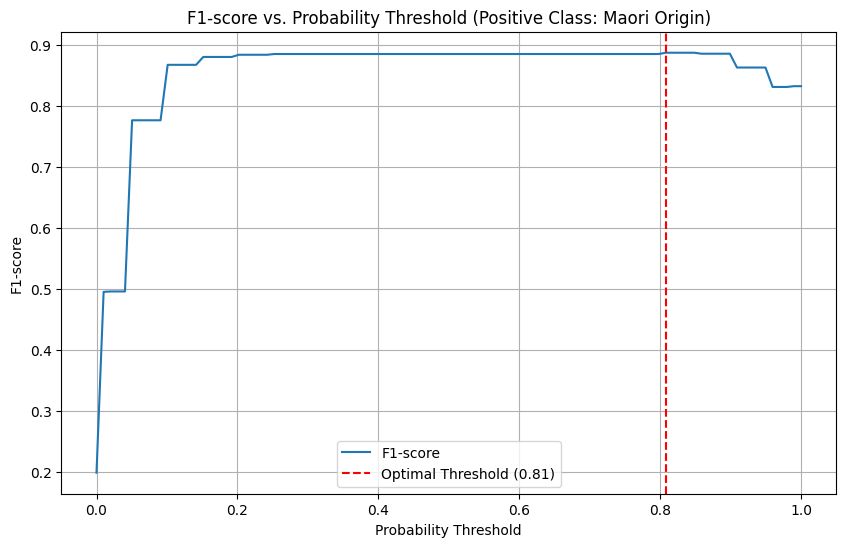

In [31]:
from sklearn.metrics import precision_recall_curve, f1_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure y_true_binary and y_scores are arrays for efficient thresholding
y_true_binary_np = np.array(y_true_binary)
y_scores_np = np.array(y_scores)

# Generate a range of thresholds
# Using thresholds from the precision_recall_curve directly or creating a finer grid
# For better visualization, we can create a more granular range.
thresholds = np.linspace(0, 1, 100)

f1_scores_at_thresholds = []
precision_at_thresholds = []
recall_at_thresholds = []

for t in thresholds:
    # Convert scores to binary predictions based on the current threshold
    y_pred_binary_at_t = (y_scores_np >= t).astype(int)

    # Calculate F1 score
    f1 = f1_score(y_true_binary_np, y_pred_binary_at_t)
    f1_scores_at_thresholds.append(f1)

    # Optionally, also calculate precision and recall at these thresholds
    p, r, _ = precision_recall_curve(y_true_binary_np, y_scores_np)
    # Find the index of the threshold in the original precision_recall_curve output that is closest to t
    idx = np.where(thresholds == t)[0]
    # If the threshold 't' exists in the original PR curve output, use its precision and recall
    if len(idx) > 0 and idx[0] < len(p) and idx[0] < len(r):
        precision_at_thresholds.append(p[idx[0]])
        recall_at_thresholds.append(r[idx[0]])
    else:
        # Fallback if specific threshold not found in PR curve (can happen if thresholds are sparse)
        # Calculate precision and recall directly for the current threshold 't'
        tp = np.sum((y_pred_binary_at_t == 1) & (y_true_binary_np == 1))
        fp = np.sum((y_pred_binary_at_t == 1) & (y_true_binary_np == 0))
        fn = np.sum((y_pred_binary_at_t == 0) & (y_true_binary_np == 1))

        current_precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        current_recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        precision_at_thresholds.append(current_precision)
        recall_at_thresholds.append(current_recall)

# Find the threshold that yields the maximum F1-score
optimal_threshold_idx = np.argmax(f1_scores_at_thresholds)
optimal_threshold = thresholds[optimal_threshold_idx]
max_f1_score = f1_scores_at_thresholds[optimal_threshold_idx]

print(f"Optimal Threshold (for F1-score): {optimal_threshold:.4f}")
print(f"Maximum F1-score at optimal threshold: {max_f1_score:.4f}")

# Plot F1-score vs. Threshold
plt.figure(figsize=(10, 6))
sns.lineplot(x=thresholds, y=f1_scores_at_thresholds, label='F1-score')
# sns.lineplot(x=thresholds, y=precision_at_thresholds, label='Precision')
# sns.lineplot(x=thresholds, y=recall_at_thresholds, label='Recall')
plt.axvline(x=optimal_threshold, color='r', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.2f})')
plt.title('F1-score vs. Probability Threshold (Positive Class: Maori Origin)')
plt.xlabel('Probability Threshold')
plt.ylabel('F1-score')
plt.grid(True)
plt.legend()
plt.show()

In [32]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import numpy as np

# Optimal threshold determined previously
optimal_threshold = 0.9596 # Use the value from the previous output

# Generate binary predictions using the optimal threshold
y_pred_optimal_threshold = (y_scores_np >= optimal_threshold).astype(int)

print(f"### Model Performance with Optimal Threshold ({optimal_threshold:.4f}) ###")

# Recalculate Confusion Matrix
# Note: y_true_binary_np has 1 for 'maori_origin' and 0 for 'non_maori_origin'
# So, labels=[1, 0] means 'maori_origin' is the positive class in the matrix output.
conf_matrix_optimal = confusion_matrix(y_true_binary_np, y_pred_optimal_threshold, labels=[1, 0])
print("\nConfusion Matrix (Optimal Threshold):")
# Adjust display to match the original report's positive class first if desired, or keep as is.
# By default, sklearn's confusion_matrix with labels=[1, 0] will put positive class (1) first
# If we want 'maori_origin' (label 0 in original `label_to_id`) as the first row/col
# we should use labels=[0, 1] if y_true_binary_np was inverted to match this logic
# Let's keep it consistent with `y_true_binary_np` where 1 is positive (maori_origin).
# So, the output will be: [[TN, FP], [FN, TP]] if labels=[0,1] and positive is 1, so here `labels=[1,0]` means first class is `maori_origin`
# Let's use the original label_names to get the correct order for the report

# To make it comparable with the initial report, we need to map back to original labels.
# `y_true_binary_np` has 1 for 'maori_origin', 0 for 'non_maori_origin'.
# `y_pred_optimal_threshold` has 1 for 'maori_origin', 0 for 'non_maori_origin'.
# So `labels=[1,0]` means 1 ('maori_origin') is the first class, 0 ('non_maori_origin') is the second
# Let's ensure the `target_names` align with this.
# The `label_names` variable still holds ['maori_origin', 'non_maori_origin']

# To get confusion matrix rows/cols in order 'maori_origin', 'non_maori_origin' (0, 1),
# we should use labels=[0, 1] with the actual integer labels, if the positive class was 0
# Since y_true_binary_np has 1 for maori and 0 for non-maori, the confusion matrix will be for [1, 0]
# Let's re-map `y_true_binary_np` and `y_pred_optimal_threshold` to be 0 and 1 as they were before `label_to_id`

# `y_true_binary_np` has 1 for positive class ('maori_origin') and 0 for negative class.
# `y_pred_optimal_threshold` has 1 for positive class ('maori_origin') and 0 for negative class.

# To align with the initial report's structure where 'maori_origin' is label 0, and 'non_maori_origin' is label 1:
# We need to map y_true_binary_np (where 1=maori, 0=non_maori) to (0=maori, 1=non_maori)
# And y_pred_optimal_threshold similarly.

y_true_mapped_for_report = np.array([0 if x == 1 else 1 for x in y_true_binary_np])
y_pred_mapped_for_report = np.array([0 if x == 1 else 1 for x in y_pred_optimal_threshold])

conf_matrix_optimal = confusion_matrix(y_true_mapped_for_report, y_pred_mapped_for_report, labels=[0, 1])
print(conf_matrix_optimal)

# Recalculate Classification Report
class_report_optimal = classification_report(y_true_mapped_for_report, y_pred_mapped_for_report, target_names=label_names, digits=4)
print("\nClassification Report (Optimal Threshold):")
print(class_report_optimal)

# Recalculate Accuracy
accuracy_optimal = accuracy_score(y_true_mapped_for_report, y_pred_mapped_for_report)
print(f"\nAccuracy (Optimal Threshold): {accuracy_optimal:.4f}")

# Recalculate F1 Score (macro and weighted)
f1_macro_optimal = f1_score(y_true_mapped_for_report, y_pred_mapped_for_report, average='macro')
f1_weighted_optimal = f1_score(y_true_mapped_for_report, y_pred_mapped_for_report, average='weighted')
print(f"F1 Macro (Optimal Threshold): {f1_macro_optimal:.4f}")
print(f"F1 Weighted (Optimal Threshold): {f1_weighted_optimal:.4f}")

### Model Performance with Optimal Threshold (0.9596) ###

Confusion Matrix (Optimal Threshold):
[[ 266  101]
 [   7 2944]]

Classification Report (Optimal Threshold):
                  precision    recall  f1-score   support

    maori_origin     0.9744    0.7248    0.8313       367
non_maori_origin     0.9668    0.9976    0.9820      2951

        accuracy                         0.9675      3318
       macro avg     0.9706    0.8612    0.9066      3318
    weighted avg     0.9677    0.9675    0.9653      3318


Accuracy (Optimal Threshold): 0.9675
F1 Macro (Optimal Threshold): 0.9066
F1 Weighted (Optimal Threshold): 0.9653


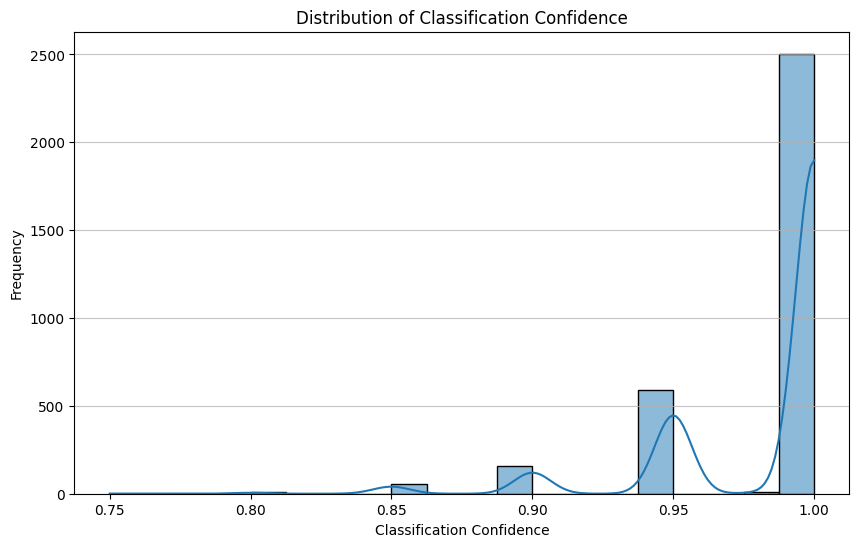

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get all classification confidence values
confidence_values = ds_test['classification_confidence']

plt.figure(figsize=(10, 6))
sns.histplot(confidence_values, bins=20, kde=True)
plt.title('Distribution of Classification Confidence')
plt.xlabel('Classification Confidence')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

End